In [62]:
# Instale através do requirements.txt: pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
import tensorflow as tf

In [63]:
# Obtendo o dataset
df = pd.read_csv("data/base_classificacao_binaria.csv")

# Etapa 1: Entendimento do Problema

### Tipo de problema
O desenvolvimento do projeto toma como base o dataset ```base_classificacao_binaria.csv``` (recorte do dataset abaixo) e se fundamenta no aprendizado supervisionado, dado que cada amostra possui seu respectivo rótulo de saída (```target```). Além disso, se trata de um problema de classificação, em que o modelo deve identificar os padrões nos atributos de entrada para determinar a qual classe discreta (binária, neste caso) a amostragem pertence.

### Features e Labels
O dataset já nos dá um norte bem forte sobre quais métricas escolher como ```features``` e qual escolher como ```label```. No nosso dataset temos um total de 13 colunas, sendo 11 delas numéricas, 1 de índice de 1 de dados em string. A última coluna é uma coluna de valores binários chamada de ```target```, e é justamente o que queremos prever com base nos dados das colunas anteriores. 

Sabendo disso, iremos adotar as seguintes _features_:
```sensor_a```, ```sensor_b```, ```sensor_c```, ```measurement_d```, ```measurement_e```, ```measurement_f```, ```measurement_g```, ```measurement_h```, ```measurement_j```, ```ratio_j``` e ```environment```.
Nosso _label_ será a coluna ```target```.



In [64]:
# Data sample
df.head()
#df.describe()

,sample_id,sensor_a,sensor_b,sensor_c,measurement_d,measurement_e,measurement_f,measurement_g,measurement_h,measurement_i,ratio_j,environment,target
0,S08268,8.914515,867.306001,0.019069,NaN,45.686368,1.700616,-0.902463,NaN,0.453651,1.017578,hot,0
1,S03978,6.648553,1092.307380,0.029332,NaN,53.110799,-0.208217,-2.485422,-1.579362,0.971668,3.516217,hot,0
2,S03450,10.803832,952.510306,0.055172,0.644110,50.427537,2.361744,NaN,-0.285890,0.326307,1.623479,hot,1
3,S00187,8.140751,669.676350,0.063204,1.174591,55.814057,0.740185,-2.444912,-1.822998,NaN,0.733792,mild,1
4,S02910,8.351185,1302.375048,0.046524,0.674800,55.144315,0.530997,-0.405251,NaN,-0.755999,0.716739,cold,0


# Etapa 2: Análise Exploratória de Dados

Nesta etapa, será realizado um diagnóstico para verificar a qualidade e a integridade dos dados do dataset. Faremos isso por meio de análises gráficas e quantitativas dos dados através das bibliotecas ```pandas``` e ```matplotlib```, se aproveitando de histogramas (para verificar a distribuição), _box-plots_ (para verificar a existência de _outliers_), ferramentas para identificar inconsistências (valores nulos ou repetidos) e plotar uma matriz de correlação que vai nos dizer quais métricas possuem correlação forte/fraca.

## Etapa 2.1: Análise de distribuição dos dados através de histogramas
Nesta etapa, será realizada uma análise da distribuição dos dados utilizando histogramas. As informações que os histogramas nos dão são valiosas, uma vez que a partir dele conseguimos detectar discrepâncias entre as medidas de cada coluna e se elas seguem uma distribuição normal (importante para as etapas de imputação e escalonamento dos dados). 

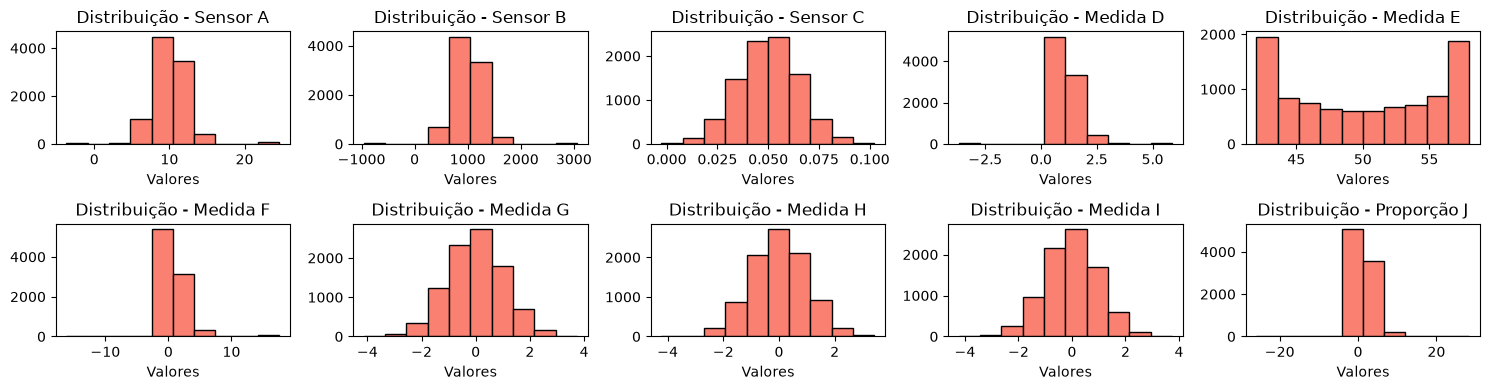

In [73]:
# Histogramas

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 4))

axes[0][0].hist(df["sensor_a"], color="salmon", edgecolor="black")
axes[0][0].set_title("Distribuição - Sensor A")
axes[0][0].set_xlabel("Valores")

axes[0][1].hist(df["sensor_b"], color="salmon", edgecolor="black")
axes[0][1].set_title("Distribuição - Sensor B")
axes[0][1].set_xlabel("Valores")

axes[0][2].hist(df["sensor_c"], color="salmon", edgecolor="black")
axes[0][2].set_title("Distribuição - Sensor C")
axes[0][2].set_xlabel("Valores")

axes[0][3].hist(df["measurement_d"], color="salmon", edgecolor="black")
axes[0][3].set_title("Distribuição - Medida D")
axes[0][3].set_xlabel("Valores")

axes[0][4].hist(df["measurement_e"], color="salmon", edgecolor="black")
axes[0][4].set_title("Distribuição - Medida E")
axes[0][4].set_xlabel("Valores")

axes[1][0].hist(df["measurement_f"], color="salmon", edgecolor="black")
axes[1][0].set_title("Distribuição - Medida F")
axes[1][0].set_xlabel("Valores")

axes[1][1].hist(df["measurement_g"], color="salmon", edgecolor="black")
axes[1][1].set_title("Distribuição - Medida G")
axes[1][1].set_xlabel("Valores")

axes[1][2].hist(df["measurement_h"], color="salmon", edgecolor="black")
axes[1][2].set_title("Distribuição - Medida H")
axes[1][2].set_xlabel("Valores")

axes[1][3].hist(df["measurement_i"], color="salmon", edgecolor="black")
axes[1][3].set_title("Distribuição - Medida I")
axes[1][3].set_xlabel("Valores")

axes[1][4].hist(df["ratio_j"], color="salmon", edgecolor="black")
axes[1][4].set_title("Distribuição - Proporção J")
axes[1][4].set_xlabel("Valores")

plt.tight_layout()
plt.show()

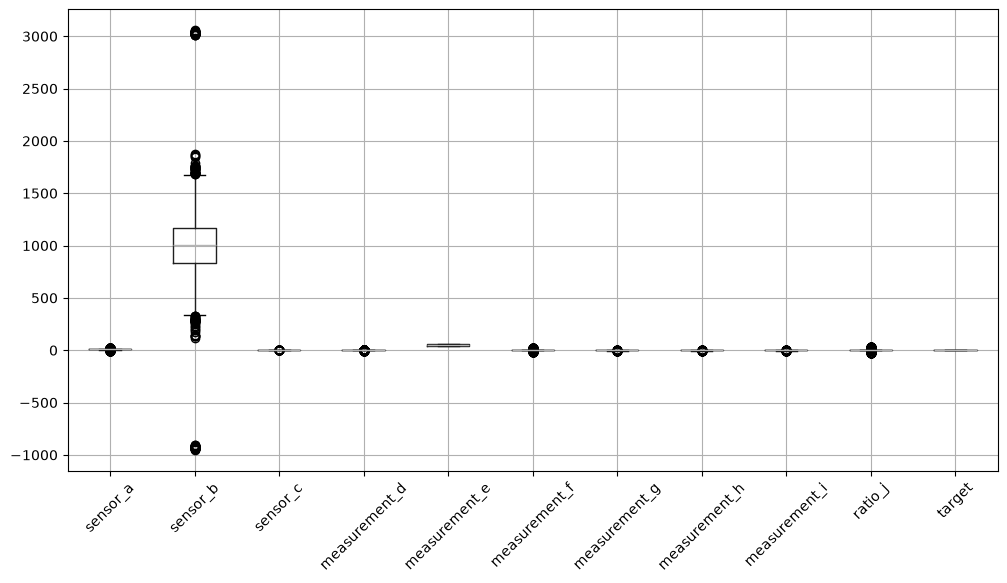

In [68]:
# boxplot
df.boxplot(figsize=(12, 6))
plt.xticks(rotation=45)
plt.show()

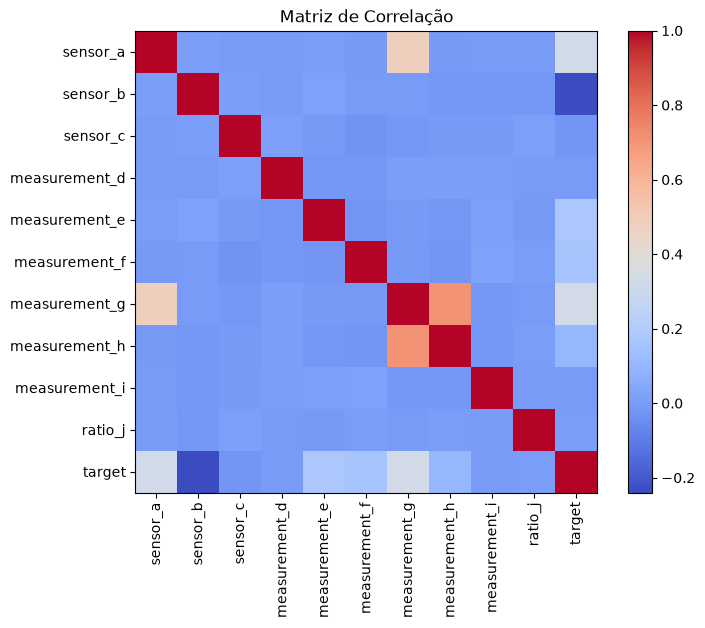

In [54]:
# Matriz de correlação linear (Pearson)
corr_matrix_crop = df.drop(["sample_id", "environment"], axis=1)
corr_matrix = corr_matrix_crop.corr()

# Visualização simples da matriz
plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)
plt.title("Matriz de Correlação")
plt.show()